# Abstention Fine-Tuning en RAG gobernado por Split Conformal Prediction

## Sección 0: Resumen, Arquitectura del Sistema y Dependencias

Este notebook implementa una arquitectura de **Retrieval-Augmented Generation (RAG) con abstención calibrada estadísticamente**, diseñada para responder preguntas fundamentadas estrictamente en un contexto documental y abstenerse explícitamente cuando la evidencia no es suficiente, garantizando cobertura libre de distribución de al menos $1 - \alpha$ incluso bajo cambios en la proporción de clases (*Label Shift*).

### Arquitectura del Sistema
1. **Backbone & Cuantización (`QLoRA 4-bit`)**: `Qwen/Qwen2.5-1.5B-Instruct` cargado en precisión normalizada de 4 bits (`nf4`) mediante `bitsandbytes`, con adaptadores de bajo rango (`LoRA`) aplicados sobre las proyecciones de atención (`q_proj`, `k_proj`, `v_proj`, `o_proj`) y MLP (`gate_proj`, `up_proj`, `down_proj`), entrenado en `float16` con `torch.amp.autocast` y `GradScaler` en GPU Tesla T4 (15 GB VRAM).
2. **Particionado Estricto Cero-Contaminación (`ServiceNow/repliqa`)**: Tres particiones 100% disjuntas (`Train`: $n=1200$, `Calibration`: $n=300$, `Test`: $n=200$) con simulación explícita de *Label Shift* en evaluación (35% incontestables en entrenamiento/calibración vs. 50% incontestables en prueba).
3. **Abstention Fine-Tuning Explícito en PyTorch Puro**: Bucle de entrenamiento personalizado con enmascaramiento exacto de pérdida (`labels = -100`) sobre sistema, contexto, pregunta y padding, optimizando exclusivamente los tokens de respuesta o la cadena canónica `ABSTAIN: The provided context does not contain enough information to answer this question.`.
4. **Capa Estadística de Split Conformal Prediction (SCP)**:
   - **Standard Marginal SCP (LAC)** *(Sadinle et al., 2019)*: Un único umbral global $\hat{q}$ calibrado sobre $s_i = 1 - \hat{\pi}_{y_i}(x_i)$.
   - **Label-Shift Weighted SCP + BBSE** *(Lipton et al., 2018; Tibshirani et al., 2019; Podkopaev & Ramdas, 2021)*: Estimación de prevalencia objetivo sin etiquetas en `Test` mediante *Black Box Shift Estimation* (BBSE) y cuantiles ponderados por razón de verosimilitud de etiquetas $\hat{w}(y) = \hat{\pi}_{\text{test}}(y) / \hat{\pi}_{\text{cal}}(y)$.
   - **Class-Conditional / Mondrian SCP** *(Vovk et al., 2005)*: Cuantiles independientes $(\hat{q}_0, \hat{q}_1)$ por clase que garantizan cobertura condicional $\mathbb{P}(Y \in C(X) \mid Y = y) \ge 1 - \alpha$ invariante ante cualquier *Label Shift*.

### Referencias Académicas
- **RepLiQA**: Monteiro et al. (2024). *RepLiQA: A Question-Answering Dataset for Benchmarking LLMs on Unseen Reference Content*.
- **R-Tuning**: Zhang et al. (2024). *R-Tuning: Instructing Large Language Models to Say 'I Don't Know'*. NAACL 2024.
- **Least Ambiguous Set-Valued Classifiers (LAC)**: Sadinle, M., Lei, J., & Wasserman, L. (2019). *Least Ambiguous Set-Valued Classifiers with Bounded Error Levels*. JASA.
- **Black Box Shift Estimation (BBSE)**: Lipton, Z., Wang, Y. X., & Smola, A. (2018). *Detecting and Correcting for Label Shift with Black Box Predictors*. ICML 2018.
- **Conformal Prediction under Covariate/Label Shift**: Tibshirani, R. J., Barber, R. F., Candès, E., & Ramdas, A. (2019); Podkopaev, A., & Ramdas, A. (2021).
- **Mondrian Conformal Prediction**: Vovk, V., Gammerman, A., & Shafer, G. (2005). *Algorithmic Learning in a Random World*.

In [1]:
%%capture
!pip install -q -U transformers accelerate bitsandbytes peft datasets scipy matplotlib pandas scikit-learn

In [2]:
import os
import sys
import json
import math
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Desactivar las funciones de detección de torchvision y torchaudio en transformers
import transformers.utils.import_utils as _iu
_iu.is_torchvision_available = lambda: False
_iu.is_torchaudio_available = lambda: False

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    get_cosine_schedule_with_warmup,
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
    PeftModel,
)

warnings.filterwarnings("ignore")

# Configuración global determinista
SEED = 42
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
ABSTAIN_PREFIX = "ABSTAIN:"
ABSTAIN_CANONICAL = "ABSTAIN: The provided context does not contain enough information to answer this question."
MAX_SEQ_LEN = 1024

print(f"Dispositivo activo: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Dispositivo activo: cuda
GPU: Tesla T4 | VRAM Total: 15.64 GB


## Sección 1: Configuración Global, Semillas y Construcción de Splits Disjuntos

Configuramos el entorno determinista (`SEED = 42`), validamos disponibilidad de GPU T4 y construimos las tres particiones 100% disjuntas desde `ServiceNow/repliqa` (`split="repliqa_0"`):
- **`Train`**: $1,200$ muestras ($65\%$ respondibles / $35\%$ incontestables).
- **`Calibration`**: $300$ muestras ($65\%$ respondibles / $35\%$ incontestables).
- **`Test`**: $200$ muestras ($50\%$ respondibles / $50\%$ incontestables), induciendo un **Label Shift** realista de $+15\%$ en la tasa de consultas sin soporte documental.

In [3]:
import os
import json
import math
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    get_cosine_schedule_with_warmup,
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
    PeftModel,
)

warnings.filterwarnings("ignore")

# Configuración global determinista
SEED = 42
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
ABSTAIN_PREFIX = "ABSTAIN:"
ABSTAIN_CANONICAL = "ABSTAIN: The provided context does not contain enough information to answer this question."
MAX_SEQ_LEN = 1024

print(f"Dispositivo activo: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Dispositivo activo: cuda
GPU: Tesla T4 | VRAM Total: 15.64 GB


In [4]:
# Carga y particionado estricto cero-contaminación de ServiceNow/repliqa
raw_ds = load_dataset("ServiceNow/repliqa", split="repliqa_0")

def is_unanswerable(example: Dict[str, Any]) -> bool:
    ans = str(example.get("answer", "")).strip()
    long_ans = str(example.get("long_answer", "")).strip()
    return ("not found in the document" in ans.lower()) or (long_ans == "NA")

# Separar índices por clase (0 = respondible, 1 = incontestable / abstención)
answerable_records = []
unanswerable_records = []

for idx, row in enumerate(raw_ds):
    unans = is_unanswerable(row)
    record = {
        "orig_idx": idx,
        "context": str(row["document_extracted"]).strip(),
        "question": str(row["question"]).strip(),
        "answer": ABSTAIN_CANONICAL if unans else str(row["answer"]).strip(),
        "label": 1 if unans else 0,  # 0: ANSWER, 1: ABSTAIN
    }
    if unans:
        unanswerable_records.append(record)
    else:
        answerable_records.append(record)

# Barajar determinísticamente con semilla fija antes de particionar
rng = np.random.default_rng(SEED)
rng.shuffle(answerable_records)
rng.shuffle(unanswerable_records)

# Tamaños requeridos por partición
# Train: 1200 (65% ans = 780, 35% unans = 420)
# Cal:    300 (65% ans = 195, 35% unans = 105)
# Test:   200 (50% ans = 100, 50% unans = 100)
n_train_ans, n_train_unans = 780, 420
n_cal_ans, n_cal_unans = 195, 105
n_test_ans, n_test_unans = 100, 100

assert len(answerable_records) >= (n_train_ans + n_cal_ans + n_test_ans), "Insuficientes muestras respondibles"
assert len(unanswerable_records) >= (n_train_unans + n_cal_unans + n_test_unans), "Insuficientes muestras incontestables"

train_data = (
    answerable_records[:n_train_ans] +
    unanswerable_records[:n_train_unans]
)
cal_data = (
    answerable_records[n_train_ans : n_train_ans + n_cal_ans] +
    unanswerable_records[n_train_unans : n_train_unans + n_cal_unans]
)
test_data = (
    answerable_records[n_train_ans + n_cal_ans : n_train_ans + n_cal_ans + n_test_ans] +
    unanswerable_records[n_train_unans + n_cal_unans : n_train_unans + n_cal_unans + n_test_unans]
)

# Barajar cada split internamente
rng.shuffle(train_data)
rng.shuffle(cal_data)
rng.shuffle(test_data)

# Verificación estricta de cero fuga de datos (intersección vacía de orig_idx)
train_ids = {r["orig_idx"] for r in train_data}
cal_ids = {r["orig_idx"] for r in cal_data}
test_ids = {r["orig_idx"] for r in test_data}

assert len(train_ids & cal_ids) == 0, "Fuga detectada entre Train y Calibration"
assert len(train_ids & test_ids) == 0, "Fuga detectada entre Train y Test"
assert len(cal_ids & test_ids) == 0, "Fuga detectada entre Calibration y Test"

# Tabla resumen de balance de clases
summary_rows = []
for split_name, split_list in [("Train", train_data), ("Calibration", cal_data), ("Test (Label Shift)", test_data)]:
    total = len(split_list)
    n_ans = sum(1 for r in split_list if r["label"] == 0)
    n_abs = sum(1 for r in split_list if r["label"] == 1)
    summary_rows.append({
        "Partición": split_name,
        "Total": total,
        "Respondibles (y=0)": f"{n_ans} ({n_ans/total:.1%})",
        "Incontestables (y=1)": f"{n_abs} ({n_abs/total:.1%})",
        "IDs Únicos": len({r["orig_idx"] for r in split_list})
    })

df_splits = pd.DataFrame(summary_rows)
print("Verificación de particiones 100% disjuntas completada sin fuga de datos:")
display(df_splits)

README.md:   0%|          | 0.00/8.10k [00:00<?, ?B/s]

data/repliqa_0-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.9MB            

data/repliqa_0-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/repliqa_1-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.9MB            

data/repliqa_1-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/repliqa_2-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.9MB            

... (8 outputs left out)

Generating repliqa_3 split:   0%|          | 0/17955 [00:00<?, ? examples/s]

Generating repliqa_4 split:   0%|          | 0/17950 [00:00<?, ? examples/s]

Verificación de particiones 100% disjuntas completada sin fuga de datos:


,Partición,Total,Respondibles (y=0),Incontestables (y=1),IDs Únicos
0,Train,1200,780 (65.0%),420 (35.0%),1200
1,Calibration,300,195 (65.0%),105 (35.0%),300
2,Test (Label Shift),200,100 (50.0%),100 (50.0%),200


## Sección 2: `Dataset`, `DataLoader` y Verificación Visual del Loss Masking (`labels = -100`)

Construimos un `Dataset` y una función `collate_fn` personalizados sobre el `chat_template` oficial de `Qwen2.5-1.5B-Instruct`:
- **Prompt de Entrada (`prompt_ids`)**: Incluye los turnos `system` (instrucciones estrictas de grounding documental y formato `ABSTAIN:`) y `user` (Contexto + Pregunta), además del encabezado de inicio de turno del asistente (`<|im_start|>assistant\n`). Todos estos tokens reciben `label = -100` para evitar calcular pérdida autorregresiva sobre el contexto.
- **Objetivo Supervisado (`target_ids`)**: Contiene exclusivamente la respuesta del asistente (o la cadena canónica `ABSTAIN: ...`) más `<|im_end|>`. Únicamente estos tokens contribuyen al gradiente.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

SYSTEM_PROMPT = (
    "You are a strict grounded QA assistant. Answer the user's question using ONLY facts explicitly stated "
    "in the provided Context. If the Context does not contain sufficient information to answer the question "
    "accurately, you must abstain by replying exactly with: "
    "'ABSTAIN: The provided context does not contain enough information to answer this question.'"
)

def build_prompt_messages(context: str, question: str) -> List[Dict[str, str]]:
    user_content = f"Context:\n{context}\n\nQuestion:\n{question}"
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_content},
    ]

class RepLiQAAbstentionDataset(Dataset):
    def __init__(self, records: List[Dict[str, Any]], tokenizer, max_length: int = 1024):
        self.samples = []
        self.tokenizer = tokenizer
        self.max_length = max_length

        for rec in records:
            messages = build_prompt_messages(rec["context"], rec["question"])
            prompt_text = tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True
            )
            target_text = rec["answer"] + tokenizer.eos_token

            prompt_ids = tokenizer.encode(prompt_text, add_special_tokens=False)
            target_ids = tokenizer.encode(target_text, add_special_tokens=False)

            # Truncar contexto desde la izquierda si excede max_length preservando pregunta y target
            max_prompt_len = self.max_length - len(target_ids)
            if max_prompt_len < 64:
                target_ids = target_ids[:128]
                max_prompt_len = self.max_length - len(target_ids)

            if len(prompt_ids) > max_prompt_len:
                # Preservar encabezado de sistema (primeros 60 tokens) y cola (pregunta + assistant header)
                head_len = 60
                tail_len = max_prompt_len - head_len
                prompt_ids = prompt_ids[:head_len] + prompt_ids[-tail_len:]

            input_ids = prompt_ids + target_ids
            labels = ([-100] * len(prompt_ids)) + target_ids

            self.samples.append({
                "input_ids": input_ids,
                "labels": labels,
                "prompt_ids": prompt_ids,
                "label_class": rec["label"],
                "question": rec["question"],
                "context": rec["context"],
                "answer": rec["answer"],
            })

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        return self.samples[idx]

def causal_lm_collate_fn(batch: List[Dict[str, Any]], pad_token_id: int) -> Dict[str, torch.Tensor]:
    max_len = max(len(item["input_ids"]) for item in batch)
    batch_input_ids = []
    batch_attention_mask = []
    batch_labels = []

    for item in batch:
        seq_len = len(item["input_ids"])
        pad_len = max_len - seq_len

        # Right-padding para entrenamiento causal con enmascaramiento -100
        padded_input = item["input_ids"] + [pad_token_id] * pad_len
        attn_mask = [1] * seq_len + [0] * pad_len
        padded_labels = item["labels"] + [-100] * pad_len

        batch_input_ids.append(padded_input)
        batch_attention_mask.append(attn_mask)
        batch_labels.append(padded_labels)

    return {
        "input_ids": torch.tensor(batch_input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(batch_attention_mask, dtype=torch.long),
        "labels": torch.tensor(batch_labels, dtype=torch.long),
    }

train_dataset = RepLiQAAbstentionDataset(train_data, tokenizer, max_length=MAX_SEQ_LEN)
cal_dataset = RepLiQAAbstentionDataset(cal_data, tokenizer, max_length=MAX_SEQ_LEN)
test_dataset = RepLiQAAbstentionDataset(test_data, tokenizer, max_length=MAX_SEQ_LEN)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=lambda b: causal_lm_collate_fn(b, tokenizer.pad_token_id),
)

# Verificación visual del Loss Masking (-100) en un batch real
sample_batch = next(iter(train_loader))
for b_idx in range(sample_batch["input_ids"].shape[0]):
    inp = sample_batch["input_ids"][b_idx]
    lbl = sample_batch["labels"][b_idx]
    masked_count = (lbl == -100).sum().item()
    active_ids = inp[lbl != -100]
    decoded_target = tokenizer.decode(active_ids, skip_special_tokens=False)
    print(f"--- Ejemplo {b_idx + 1} en Batch ---")
    print(f"Longitud total tensor: {len(inp)} | Tokens enmascarados (-100): {masked_count} | Tokens activos en pérdida: {len(active_ids)}")
    print(f"Texto decodificado con gradiente activo:\n{decoded_target!r}\n")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

--- Ejemplo 1 en Batch ---
Longitud total tensor: 1024 | Tokens enmascarados (-100): 1003 | Tokens activos en pérdida: 21
Texto decodificado con gradiente activo:
'Outdated equipment, a shortage of emergency vehicles, and the need for additional training for first responders.<|im_end|>'

--- Ejemplo 2 en Batch ---
Longitud total tensor: 1024 | Tokens enmascarados (-100): 1006 | Tokens activos en pérdida: 18
Texto decodificado con gradiente activo:
'Governments could face sanctions and international legal actions for violating freedom of expression and press.<|im_end|>'



## Sección 3: Carga del Modelo QLoRA 4-bits y Evaluación Baseline Pre-SFT

Cargamos `Qwen/Qwen2.5-1.5B-Instruct` cuantizado en 4 bits (`nf4`, cómputo en `torch.float16`), preparamos el modelo para entrenamiento k-bit activando *gradient checkpointing* no reentrante (`use_reentrant=False`) e inyectamos adaptadores `LoRA` (`r=16`, `lora_alpha=32`, `lora_dropout=0.05`) sobre las capas de atención y proyección MLP.

Antes de cualquier actualización de pesos, evaluamos el comportamiento **Baseline Pre-SFT** sobre el conjunto `Test` para medir la tasa base de abstención ante preguntas incontestables frente a la tasa de respuesta en preguntas contestables.

In [6]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.float16,
)

# Preparación para QLoRA usando gradient checkpointing moderno sin métodos deprecados
base_model = prepare_model_for_kbit_training(
    base_model,
    use_gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
)
base_model.config.use_cache = False

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

@torch.no_grad()
def evaluate_greedy_generation(
    eval_model,
    dataset: RepLiQAAbstentionDataset,
    tokenizer,
    batch_size: int = 16,
    max_new_tokens: int = 48,
) -> Dict[str, Any]:
    eval_model.eval()
    eval_model.config.use_cache = True
    orig_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"

    preds_abstain = []
    true_labels = [item["label_class"] for item in dataset]
    generated_texts = []

    for start in range(0, len(dataset), batch_size):
        batch_items = [dataset[i] for i in range(start, min(start + batch_size, len(dataset)))]
        prompt_texts = [tokenizer.decode(item["prompt_ids"], skip_special_tokens=False) for item in batch_items]

        enc = tokenizer(
            prompt_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SEQ_LEN - max_new_tokens,
        ).to(DEVICE)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            out_ids = eval_model.generate(
                **enc,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

        prompt_width = enc["input_ids"].shape[1]
        for row_idx in range(out_ids.shape[0]):
            gen_tokens = out_ids[row_idx, prompt_width:]
            text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
            generated_texts.append(text)
            is_abs = int(text.upper().startswith("ABSTAIN:"))
            preds_abstain.append(is_abs)

    tokenizer.padding_side = orig_padding_side
    eval_model.config.use_cache = False

    y_true = np.array(true_labels)
    y_pred = np.array(preds_abstain)

    # y=1: incontestable (debe abstenerse); y=0: respondible (debe responder)
    unans_mask = (y_true == 1)
    ans_mask = (y_true == 0)

    abstain_recall_unans = (y_pred[unans_mask] == 1).mean()
    answer_rate_ans = (y_pred[ans_mask] == 0).mean()
    overall_acc = (y_pred == y_true).mean()

    return {
        "overall_acc": float(overall_acc),
        "abstain_recall_unans": float(abstain_recall_unans),
        "answer_rate_ans": float(answer_rate_ans),
        "y_true": y_true,
        "y_pred": y_pred,
        "generated_texts": generated_texts,
    }

pre_sft_metrics = evaluate_greedy_generation(model, test_dataset, tokenizer, batch_size=16)
print("=== Evaluación Baseline Pre-SFT (Test Set, n=200) ===")
print(f"Exactitud Global (Decisión Abstención vs Respuesta): {pre_sft_metrics['overall_acc']:.2%}")
print(f"Tasa de Abstención Correcta en Incontestables (Recall y=1): {pre_sft_metrics['abstain_recall_unans']:.2%}")
print(f"Tasa de Respuesta en Respondibles (Recall y=0): {pre_sft_metrics['answer_rate_ans']:.2%}")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
=== Evaluación Baseline Pre-SFT (Test Set, n=200) ===
Exactitud Global (Decisión Abstención vs Respuesta): 50.50%
Tasa de Abstención Correcta en Incontestables (Recall y=1): 2.00%
Tasa de Respuesta en Respondibles (Recall y=0): 99.00%


## Sección 4: Bucle de Entrenamiento Explícito en PyTorch Puro y Evaluación Post-SFT Greedy

Implementamos el bucle de entrenamiento directamente en PyTorch sin librerías envoltorio opacas (`SFTTrainer`):
- **Micro-batch & Acumulación**: `batch_size = 2`, `grad_accum = 8` (batch efectivo $= 16$).
- **Precisión Mixta Segura en T4**: `torch.amp.autocast("cuda", dtype=torch.float16)` junto con `torch.amp.GradScaler("cuda")`.
- **Optimización y Estabilidad**: `AdamW` ($	ext{lr} = 2 	imes 10^{-4}$, $	ext{weight\_decay} = 0.01$), recorte de norma de gradiente (`clip_grad_norm_` con `max_norm = 1.0`) y *scheduler* coseno con *warmup* del $10\%$.

In [7]:
EPOCHS = 2
BATCH_SIZE = 2
GRAD_ACCUM = 8
LR = 2e-4
MAX_GRAD_NORM = 1.0

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=0.01,
)

total_update_steps = math.ceil(len(train_loader) / GRAD_ACCUM) * EPOCHS
warmup_steps = max(1, int(0.10 * total_update_steps))

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_update_steps,
)

scaler = torch.amp.GradScaler("cuda")

model.train()
model.config.use_cache = False
optimizer.zero_grad()

global_step = 0
running_loss = 0.0
loss_history = []

print(f"Iniciando entrenamiento explícito: {EPOCHS} épocas | {len(train_loader)} micro-batches/época | {total_update_steps} pasos de optimización")

for epoch in range(1, EPOCHS + 1):
    for step, batch in enumerate(train_loader, start=1):
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
        labels = batch["labels"].to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            loss = outputs.loss / GRAD_ACCUM

        scaler.scale(loss).backward()
        running_loss += loss.item()

        if (step % GRAD_ACCUM == 0) or (step == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
            global_step += 1

            loss_history.append({
                "step": global_step,
                "epoch": epoch,
                "loss": running_loss,
                "lr": scheduler.get_last_lr()[0],
            })

            if global_step % 15 == 0 or global_step == total_update_steps:
                print(
                    f"Época {epoch}/{EPOCHS} | Paso {global_step:03d}/{total_update_steps:03d} | "
                    f"Loss: {running_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.2e}"
                )
            running_loss = 0.0

post_sft_metrics = evaluate_greedy_generation(model, test_dataset, tokenizer, batch_size=16)
print("\n=== Evaluación Post-SFT Greedy (Test Set, n=200) ===")
print(f"Exactitud Global: {post_sft_metrics['overall_acc']:.2%} (Pre-SFT: {pre_sft_metrics['overall_acc']:.2%})")
print(f"Abstención Correcta en Incontestables (Recall y=1): {post_sft_metrics['abstain_recall_unans']:.2%} (Pre-SFT: {pre_sft_metrics['abstain_recall_unans']:.2%})")
print(f"Tasa de Respuesta en Respondibles (Recall y=0): {post_sft_metrics['answer_rate_ans']:.2%} (Pre-SFT: {pre_sft_metrics['answer_rate_ans']:.2%})")

Iniciando entrenamiento explícito: 2 épocas | 600 micro-batches/época | 150 pasos de optimización
Época 1/2 | Paso 015/150 | Loss: 0.7722 | LR: 2.00e-04
Época 1/2 | Paso 030/150 | Loss: 0.9901 | LR: 1.94e-04
Época 1/2 | Paso 045/150 | Loss: 0.7536 | LR: 1.77e-04
Época 1/2 | Paso 060/150 | Loss: 0.6307 | LR: 1.50e-04
Época 1/2 | Paso 075/150 | Loss: 0.4997 | LR: 1.17e-04
Época 2/2 | Paso 090/150 | Loss: 0.6021 | LR: 8.26e-05
Época 2/2 | Paso 105/150 | Loss: 0.3849 | LR: 5.00e-05
Época 2/2 | Paso 120/150 | Loss: 0.5152 | LR: 2.34e-05
Época 2/2 | Paso 135/150 | Loss: 0.4378 | LR: 6.03e-06
Época 2/2 | Paso 150/150 | Loss: 0.4383 | LR: 0.00e+00

=== Evaluación Post-SFT Greedy (Test Set, n=200) ===
Exactitud Global: 50.00% (Pre-SFT: 50.50%)
Abstención Correcta en Incontestables (Recall y=1): 5.00% (Pre-SFT: 2.00%)
Tasa de Respuesta en Respondibles (Recall y=0): 95.00% (Pre-SFT: 99.00%)


## Sección 5: Fundamento Matemático, `compute_abstain_prob` y Calibración Conformal

### 5.1 Extracción Exacta de Probabilidad de Abstención en Espacio Logarítmico
Sea $x$ la secuencia tokenizada del *prompt* (sistema, contexto, pregunta y cabecera `<|im_start|>assistant\n`), y sea $(t_1, t_2, \dots, t_K)$ la secuencia exacta de sub-tokens correspondiente al prefijo `"ABSTAIN:"`. Por la regla de la cadena de probabilidad condicional autorregresiva:

$$\log P(\text{"ABSTAIN:"} \mid x) = \sum_{k=1}^{K} \log P_\theta(t_k \mid x, t_1, \dots, t_{k-1})$$

Calculamos todos los logits en **un único forward pass** concatenando `prompt_ids + prefix_ids`, extrayendo `log_softmax` en precisión `float32` para estabilidad numérica y exponenciando:

$$\hat{\pi}_1(x) = P(\text{"ABSTAIN:"} \mid x) = \exp\left(\sum_{k=1}^{K} \log P_\theta(t_k \mid x, t_{<k})\right), \quad \hat{\pi}_0(x) = 1 - \hat{\pi}_1(x)$$

Definimos la función de **score de no-conformidad** (Sadinle et al., 2019) para cada etiqueta candidata $y \in \{0, 1\}$:

$$s(x, y) = 1 - \hat{\pi}_y(x)$$

---

### 5.2 Los Tres Esquemas de Split Conformal Prediction ($\alpha = 0.10$, meta $1 - \alpha = 90\%$)

Dado un conjunto de calibración $\mathcal{D}_{\text{cal}} = \{(X_i, Y_i)\}_{i=1}^n$ independiente de entrenamiento y prueba:

1. **Método 1 — Standard Marginal SCP (LAC)**:
   Calcula un único cuantil global de muestra finita sobre $s_i = 1 - \hat{\pi}_{Y_i}(X_i)$:
   $$\hat{q} = \text{Quantile}\left(\{s_1, \dots, s_n, +\infty\}; \frac{\lceil (n+1)(1 - \alpha) \rceil}{n+1}\right)$$
   Conjunto de predicción: $C_{\text{LAC}}(x) = \{y \in \{0, 1\} : 1 - \hat{\pi}_y(x) \le \hat{q}\}$. Bajo intercambio (*exchangeability*), garantiza $\mathbb{P}(Y_{n+1} \in C_{\text{LAC}}(X_{n+1})) \ge 1 - \alpha$, pero **pierde cobertura marginal bajo Label Shift** si la clase que aumenta en `Test` tiene mayor dispersión de scores.

2. **Método 2 — Label-Shift Weighted SCP + BBSE (Lipton et al., 2018; Tibshirani et al., 2019)**:
   Estima las prevalencias desconocidas en `Test` $\hat{\mu}_{\text{test}} = (\hat{p}_0, \hat{p}_1)^\top$ sin usar etiquetas reales de `Test` mediante **Black Box Shift Estimation (BBSE)**:
   - Sea $\hat{Y} = \mathbb{I}[\hat{\pi}_1(X) \ge 0.5]$ el predictor duro base.
   - Sobre `Calibration`, se estima la matriz de confusión normalizada por clase verdadera $C_{j, y} = \hat{\mathbb{P}}_{\text{cal}}(\hat{Y} = j \mid Y = y)$.
   - Resolviendo el sistema lineal $\hat{\mu}_{\text{test}} = \text{Clip}_{\Delta^1}(C^{-1} \hat{q}_{\text{test}})$, donde $\hat{q}_{\text{test}}$ es la distribución de predicciones duras en `Test`, se obtienen los pesos de razón de verosimilitud:
     $$\hat{w}(y) = \frac{\hat{\mu}_{\text{test}}(y)}{\hat{\mu}_{\text{cal}}(y)}, \quad p_i = \frac{\hat{w}(Y_i)}{\sum_{j=1}^n \hat{w}(Y_j) + \hat{w}(y)}, \quad p_{n+1}(y) = \frac{\hat{w}(y)}{\sum_{j=1}^n \hat{w}(Y_j) + \hat{w}(y)}$$
   - El umbral $\hat{q}_w(y)$ es el cuantil $(1 - \alpha)$ de la distribución discreta ponderada $\sum_{i=1}^n p_i \delta_{s_i} + p_{n+1}(y) \delta_{+\infty}$.

3. **Método 3 — Class-Conditional / Mondrian SCP (Vovk et al., 2005)**:
   Particiona $\mathcal{D}_{\text{cal}}$ por etiqueta $\mathcal{I}_y = \{i \in [n] : Y_i = y\}$ con tamaño $n_y = |\mathcal{I}_y|$ y calibra un cuantil independiente por clase:
   $$\hat{q}_y = \text{Quantile}\left(\{s_i : i \in \mathcal{I}_y\} \cup \{+\infty\}; \frac{\lceil (n_y + 1)(1 - \alpha) \rceil}{n_y + 1}\right), \quad y \in \{0, 1\}$$
   Conjunto de predicción: $C_{\text{Mondrian}}(x) = \{y \in \{0, 1\} : 1 - \hat{\pi}_y(x) \le \hat{q}_y\}$. Garantiza cobertura condicional exacta por clase $\mathbb{P}(Y \in C_{\text{Mondrian}}(X) \mid Y = y) \ge 1 - \alpha$, siendo **matemáticamente inmune a cualquier cambio de proporción de clases en producción**.

In [10]:
import gc

gc.collect()
torch.cuda.empty_cache()

ABSTAIN_PREFIX_IDS = tokenizer.encode(ABSTAIN_PREFIX, add_special_tokens=False)
print(f"Sub-tokens exactos de '{ABSTAIN_PREFIX}': {ABSTAIN_PREFIX_IDS} -> {[tokenizer.decode([t]) for t in ABSTAIN_PREFIX_IDS]}")

@torch.no_grad()
def compute_abstain_prob_batch(
    eval_model,
    prompt_ids_list: List[List[int]],
    prefix_ids: List[int] = ABSTAIN_PREFIX_IDS,
    batch_size: int = 8,
) -> np.ndarray:
    """
    Calcula P('ABSTAIN:' | x) en un único forward pass aplicando la regla de la cadena
    en espacio logarítmico (log_softmax en float32) únicamente sobre las K posiciones del prefijo.
    """
    eval_model.eval()
    eval_model.config.use_cache = False
    K = len(prefix_ids)
    probs_out = []

    for start in range(0, len(prompt_ids_list), batch_size):
        chunk = prompt_ids_list[start : start + batch_size]
        seqs = [p_ids + prefix_ids for p_ids in chunk]
        max_len = max(len(s) for s in seqs)

        input_ids = []
        attention_mask = []
        prompt_lens = []

        for p_ids, full_s in zip(chunk, seqs):
            pad_len = max_len - len(full_s)
            input_ids.append(full_s + [tokenizer.pad_token_id] * pad_len)
            attention_mask.append([1] * len(full_s) + [0] * pad_len)
            prompt_lens.append(len(p_ids))

        inp_tensor = torch.tensor(input_ids, dtype=torch.long, device=DEVICE)
        mask_tensor = torch.tensor(attention_mask, dtype=torch.long, device=DEVICE)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            logits = eval_model(input_ids=inp_tensor, attention_mask=mask_tensor).logits

        # Extraer ÚNICAMENTE las K posiciones del prefijo antes de convertir a float32 (ahorra ~9 GB de VRAM)
        for b_idx, p_len in enumerate(prompt_lens):
            target_logits = logits[b_idx, p_len - 1 : p_len - 1 + K, :].float()  # (K, vocab_size)
            target_log_probs = F.log_softmax(target_logits, dim=-1)
            seq_log_prob = sum(
                target_log_probs[k, tok_id].item() for k, tok_id in enumerate(prefix_ids)
            )
            probs_out.append(math.exp(seq_log_prob))

        del logits, inp_tensor, mask_tensor

    return np.clip(np.array(probs_out, dtype=np.float64), 0.0, 1.0)

def compute_abstain_prob(eval_model, context: str, question: str) -> float:
    """Wrapper unitario para inferencia en producción."""
    messages = build_prompt_messages(context, question)
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    prompt_ids = tokenizer.encode(prompt_text, add_special_tokens=False)
    if len(prompt_ids) > MAX_SEQ_LEN - 64:
        prompt_ids = prompt_ids[:60] + prompt_ids[-(MAX_SEQ_LEN - 124):]
    return float(compute_abstain_prob_batch(eval_model, [prompt_ids], batch_size=1)[0])

# Extraer probabilidades calibradas en Calibration y Test
cal_prompts = [item["prompt_ids"] for item in cal_dataset]
test_prompts = [item["prompt_ids"] for item in test_dataset]

y_cal = np.array([item["label_class"] for item in cal_dataset], dtype=np.int64)
y_test = np.array([item["label_class"] for item in test_dataset], dtype=np.int64)

p_abs_cal = compute_abstain_prob_batch(model, cal_prompts, batch_size=8)
p_abs_test = compute_abstain_prob_batch(model, test_prompts, batch_size=8)

print(f"Probabilidades extraídas -> Calibración: {p_abs_cal.shape} | Test: {p_abs_test.shape}")
print(f"Media P(ABSTAIN:|x) en Calibración -> y=0: {p_abs_cal[y_cal==0].mean():.4f} | y=1: {p_abs_cal[y_cal==1].mean():.4f}")
print(f"Media P(ABSTAIN:|x) en Test        -> y=0: {p_abs_test[y_test==0].mean():.4f} | y=1: {p_abs_test[y_test==1].mean():.4f}")

Sub-tokens exactos de 'ABSTAIN:': [1867, 784, 6836, 25] -> ['AB', 'ST', 'AIN', ':']
Probabilidades extraídas -> Calibración: (300,) | Test: (200,)
Media P(ABSTAIN:|x) en Calibración -> y=0: 0.0062 | y=1: 0.9816
Media P(ABSTAIN:|x) en Test        -> y=0: 0.0138 | y=1: 0.9547


In [11]:
# Implementación rigurosa de los 3 esquemas de Split Conformal Prediction

def get_nonconformity_scores(p_abs: np.ndarray) -> np.ndarray:
    """
    Retorna matriz S de forma (N, 2) donde:
      S[i, 0] = 1 - P(ANSWER | x_i) = P(ABSTAIN: | x_i)
      S[i, 1] = 1 - P(ABSTAIN: | x_i)
    """
    p_ans = 1.0 - p_abs
    return np.column_stack([1.0 - p_ans, 1.0 - p_abs])

def finite_sample_quantile(scores: np.ndarray, alpha: float) -> float:
    """Cuantil estándar de muestra finita ceil((n+1)(1-alpha))/n con +inf en el extremo."""
    n = len(scores)
    level = math.ceil((n + 1) * (1.0 - alpha)) / (n + 1)
    if level > 1.0:
        return float("inf")
    augmented = np.append(np.sort(scores), float("inf"))
    idx = int(math.ceil(level * (n + 1))) - 1
    idx = min(max(idx, 0), len(augmented) - 1)
    return float(augmented[idx])

def weighted_conformal_quantile(scores: np.ndarray, weights: np.ndarray, w_new: float, alpha: float) -> float:
    """
    Cuantil ponderado (Tibshirani et al. 2019 / Podkopaev & Ramdas 2021)
    para distribución discreta sum(p_i * delta_{s_i}) + p_{n+1} * delta_{+inf}.
    """
    total_w = np.sum(weights) + w_new
    p_cal = weights / total_w
    order = np.argsort(scores)
    sorted_scores = scores[order]
    sorted_probs = p_cal[order]

    cum_probs = np.cumsum(sorted_probs)
    target = 1.0 - alpha
    idx = np.searchsorted(cum_probs, target, side="left")
    if idx >= len(sorted_scores):
        return float("inf")
    return float(sorted_scores[idx])

def estimate_bbse_weights(
    p_abs_cal: np.ndarray,
    y_cal: np.ndarray,
    p_abs_test_unlabeled: np.ndarray,
    threshold: float = 0.5,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Black Box Shift Estimation (BBSE - Lipton et al., 2018) sin etiquetas reales de Test.
    Estima pi_test(y) y retorna pesos w(y) = pi_test(y) / pi_cal(y).
    """
    yhat_cal = (p_abs_cal >= threshold).astype(int)
    yhat_test = (p_abs_test_unlabeled >= threshold).astype(int)

    # Matriz de confusión C_{j, y} = P_cal(Y_hat = j | Y = y)
    C = np.zeros((2, 2), dtype=np.float64)
    for y in [0, 1]:
        mask = (y_cal == y)
        for j in [0, 1]:
            C[j, y] = np.mean(yhat_cal[mask] == j)

    # Regularización ligera si C estuviera cerca de singularidad
    C = 0.999 * C + 0.001 * np.eye(2)

    q_test = np.array([np.mean(yhat_test == 0), np.mean(yhat_test == 1)], dtype=np.float64)
    pi_cal = np.array([np.mean(y_cal == 0), np.mean(y_cal == 1)], dtype=np.float64)

    # Inversión y proyección al simplex probabilístico Delta^1
    pi_test_est = np.linalg.solve(C, q_test)
    pi_test_est = np.clip(pi_test_est, 1e-4, 1.0 - 1e-4)
    pi_test_est = pi_test_est / np.sum(pi_test_est)

    w_y = pi_test_est / pi_cal
    return w_y, pi_test_est, pi_cal

def calibrate_all_scp_methods(
    p_abs_cal: np.ndarray,
    y_cal: np.ndarray,
    p_abs_test_unlabeled: np.ndarray,
    alpha: float = 0.10,
) -> Dict[str, Any]:
    S_cal = get_nonconformity_scores(p_abs_cal)
    true_scores_cal = S_cal[np.arange(len(y_cal)), y_cal]

    # 1. Standard Marginal SCP (LAC)
    q_lac = finite_sample_quantile(true_scores_cal, alpha)

    # 2. Label-Shift Weighted SCP + BBSE
    w_y, pi_test_est, pi_cal = estimate_bbse_weights(p_abs_cal, y_cal, p_abs_test_unlabeled)
    sample_weights = w_y[y_cal]
    q_bbse_0 = weighted_conformal_quantile(true_scores_cal, sample_weights, float(w_y[0]), alpha)
    q_bbse_1 = weighted_conformal_quantile(true_scores_cal, sample_weights, float(w_y[1]), alpha)

    # 3. Class-Conditional / Mondrian SCP
    scores_y0 = true_scores_cal[y_cal == 0]
    scores_y1 = true_scores_cal[y_cal == 1]
    q_mondrian_0 = finite_sample_quantile(scores_y0, alpha)
    q_mondrian_1 = finite_sample_quantile(scores_y1, alpha)

    return {
        "alpha": alpha,
        "q_lac": q_lac,
        "q_bbse": [q_bbse_0, q_bbse_1],
        "q_mondrian": [q_mondrian_0, q_mondrian_1],
        "bbse_pi_cal": pi_cal.tolist(),
        "bbse_pi_test_est": pi_test_est.tolist(),
        "bbse_weights": w_y.tolist(),
        "n_cal_0": int(len(scores_y0)),
        "n_cal_1": int(len(scores_y1)),
    }

ALPHA = 0.10
cal_artifacts = calibrate_all_scp_methods(p_abs_cal, y_cal, p_abs_test, alpha=ALPHA)

print(f"=== Artefactos Calibrados (alpha = {ALPHA}, meta cobertura = {1-ALPHA:.0%}) ===")
print(f"1. LAC (Standard Marginal)       -> q_hat = {cal_artifacts['q_lac']:.4f}")
print(f"2. Weighted SCP + BBSE           -> pi_test_est = {[round(x, 4) for x in cal_artifacts['bbse_pi_test_est']]} (real: [0.50, 0.50])")
print(f"                                    pesos w(y)  = {[round(x, 4) for x in cal_artifacts['bbse_weights']]}")
print(f"                                    q_w(0) = {cal_artifacts['q_bbse'][0]:.4f}, q_w(1) = {cal_artifacts['q_bbse'][1]:.4f}")
print(f"3. Mondrian (Class-Conditional)  -> q_0 (n0={cal_artifacts['n_cal_0']}) = {cal_artifacts['q_mondrian'][0]:.4f}, q_1 (n1={cal_artifacts['n_cal_1']}) = {cal_artifacts['q_mondrian'][1]:.4f}")

=== Artefactos Calibrados (alpha = 0.1, meta cobertura = 90%) ===
1. LAC (Standard Marginal)       -> q_hat = 0.0098
2. Weighted SCP + BBSE           -> pi_test_est = [0.5076, 0.4924] (real: [0.50, 0.50])
                                    pesos w(y)  = [0.7809, 1.4069]
                                    q_w(0) = 0.0171, q_w(1) = 0.0171
3. Mondrian (Class-Conditional)  -> q_0 (n0=195) = 0.0004, q_1 (n1=105) = 0.0451


## Sección 6: Evaluación Comparativa Final en `Test` (Escenario de Label Shift)

Evaluamos los tres métodos conformales sobre las $200$ muestras inéditas de `Test` ($50\%$ respondibles / $50\%$ incontestables) reportando:
- **Cobertura Global Empírica** $\widehat{\text{Cov}} = \frac{1}{m}\sum_{i=1}^m \mathbb{I}[Y_i \in C(X_i)]$ frente al objetivo $1 - \alpha = 90\%$.
- **Cobertura Condicional por Clase**: $\text{Cov}(\text{ANS})$ ($y=0$) y $\text{Cov}(\text{ABS})$ ($y=1$).
- **Operación RAG Segura**:
  - *Tasa de Incontestables Frenadas*: Porcentaje de preguntas sin evidencia ($y=1$) donde el sistema **no** emite una respuesta alucinada como decisión única ($C(X) \neq \{0\}$, es decir, $C(X) = \{1\}$ o conjunto ambiguo $\{0, 1\}$ escalado a abstención).
  - *Tasa de Respondibles Contestadas*: Porcentaje de preguntas contestables ($y=0$) resueltas de forma directa y unívoca ($C(X) = \{0\}$).
- **Distribución de Cardinalidad de Conjuntos** ($|C| = 0$ vacío, $|C| = 1$ singleton decisivo, $|C| = 2$ conjunto ambiguo).

In [12]:
def predict_conformal_sets(
    p_abs: np.ndarray,
    thresholds_per_class: Tuple[float, float],
) -> np.ndarray:
    """
    Retorna matriz booleana C de forma (N, 2) donde C[i, y] = True si y in C(x_i).
    """
    S = get_nonconformity_scores(p_abs)
    q0, q1 = thresholds_per_class
    in_0 = S[:, 0] <= q0
    in_1 = S[:, 1] <= q1
    return np.column_stack([in_0, in_1])

def evaluate_conformal_method(
    method_name: str,
    p_abs: np.ndarray,
    y_true: np.ndarray,
    thresholds: Tuple[float, float],
) -> Dict[str, Any]:
    C = predict_conformal_sets(p_abs, thresholds)
    N = len(y_true)

    covered = C[np.arange(N), y_true]
    cov_global = float(np.mean(covered))
    cov_ans = float(np.mean(covered[y_true == 0]))
    cov_abs = float(np.mean(covered[y_true == 1]))

    cardinalities = np.sum(C, axis=1)
    card_0 = float(np.mean(cardinalities == 0))
    card_1 = float(np.mean(cardinalities == 1))
    card_2 = float(np.mean(cardinalities == 2))

    # Regla operativa RAG: solo responde automáticamente si C(x) == {0} (singleton ANSWER)
    # De lo contrario (C(x) == {1}, {0,1}, o {}), frena/abstiéne por seguridad
    only_answer = (C[:, 0] == True) & (C[:, 1] == False)
    unans_stopped_rate = float(np.mean(~only_answer[y_true == 1]))
    ans_answered_rate = float(np.mean(only_answer[y_true == 0]))

    return {
        "Método Conformal": method_name,
        "Cov. Global": f"{cov_global:.2%}",
        "Cov(ANS) [y=0]": f"{cov_ans:.2%}",
        "Cov(ABS) [y=1]": f"{cov_abs:.2%}",
        "Incontestables Frenadas": f"{unans_stopped_rate:.2%}",
        "Respondibles Contestadas": f"{ans_answered_rate:.2%}",
        "|C|=0": f"{card_0:.1%}",
        "|C|=1": f"{card_1:.1%}",
        "|C|=2": f"{card_2:.1%}",
    }

results_table = [
    evaluate_conformal_method(
        "1. Standard Marginal SCP (LAC)",
        p_abs_test,
        y_test,
        (cal_artifacts["q_lac"], cal_artifacts["q_lac"]),
    ),
    evaluate_conformal_method(
        "2. Label-Shift Weighted SCP + BBSE",
        p_abs_test,
        y_test,
        tuple(cal_artifacts["q_bbse"]),
    ),
    evaluate_conformal_method(
        "3. Class-Conditional / Mondrian SCP",
        p_abs_test,
        y_test,
        tuple(cal_artifacts["q_mondrian"]),
    ),
]

df_results = pd.DataFrame(results_table)
print("=== Resultados Comparativos en Test Set Bajo Label Shift (Meta 1 - alpha = 90.0%) ===")
display(df_results)

=== Resultados Comparativos en Test Set Bajo Label Shift (Meta 1 - alpha = 90.0%) ===


,Método Conformal,Cov. Global,Cov(ANS) [y=0],Cov(ABS) [y=1],Incontestables Frenadas,Respondibles Contestadas,|C|=0,|C|=1,|C|=2
0,1. Standard Marginal SCP (LAC),86.00%,98.00%,74.00%,100.00%,98.00%,14.0%,86.0%,0.0%
1,2. Label-Shift Weighted SCP + BBSE,88.50%,98.00%,79.00%,100.00%,98.00%,11.5%,88.5%,0.0%
2,3. Class-Conditional / Mondrian SCP,88.50%,91.00%,86.00%,100.00%,91.00%,11.5%,88.5%,0.0%


## Sección 7: Visualizaciones Diagnósticas y Curva de Trade-Off Cobertura vs. Utilidad

Generamos dos paneles analíticos:
1. **Distribución de Probabilidades y Umbrales Calibrados**: Histogramas de $P(\text{"ABSTAIN:"} \mid x)$ separados por clase verdadera (`ANSWER` vs. `ABSTAIN`) junto con las fronteras de decisión inducidas por los cuantiles de LAC, Weighted+BBSE y Mondrian SCP.
2. **Curva de Trade-Off ($\alpha \in [0.02, 0.25]$)**: Evolución conjunta de la **Cobertura Empírica Global** (comparada contra la diagonal ideal $1 - \alpha$) y la **Tasa de Respuestas Contestadas** (utilidad efectiva del sistema RAG) a través de distintos niveles de riesgo conformal $\alpha$.

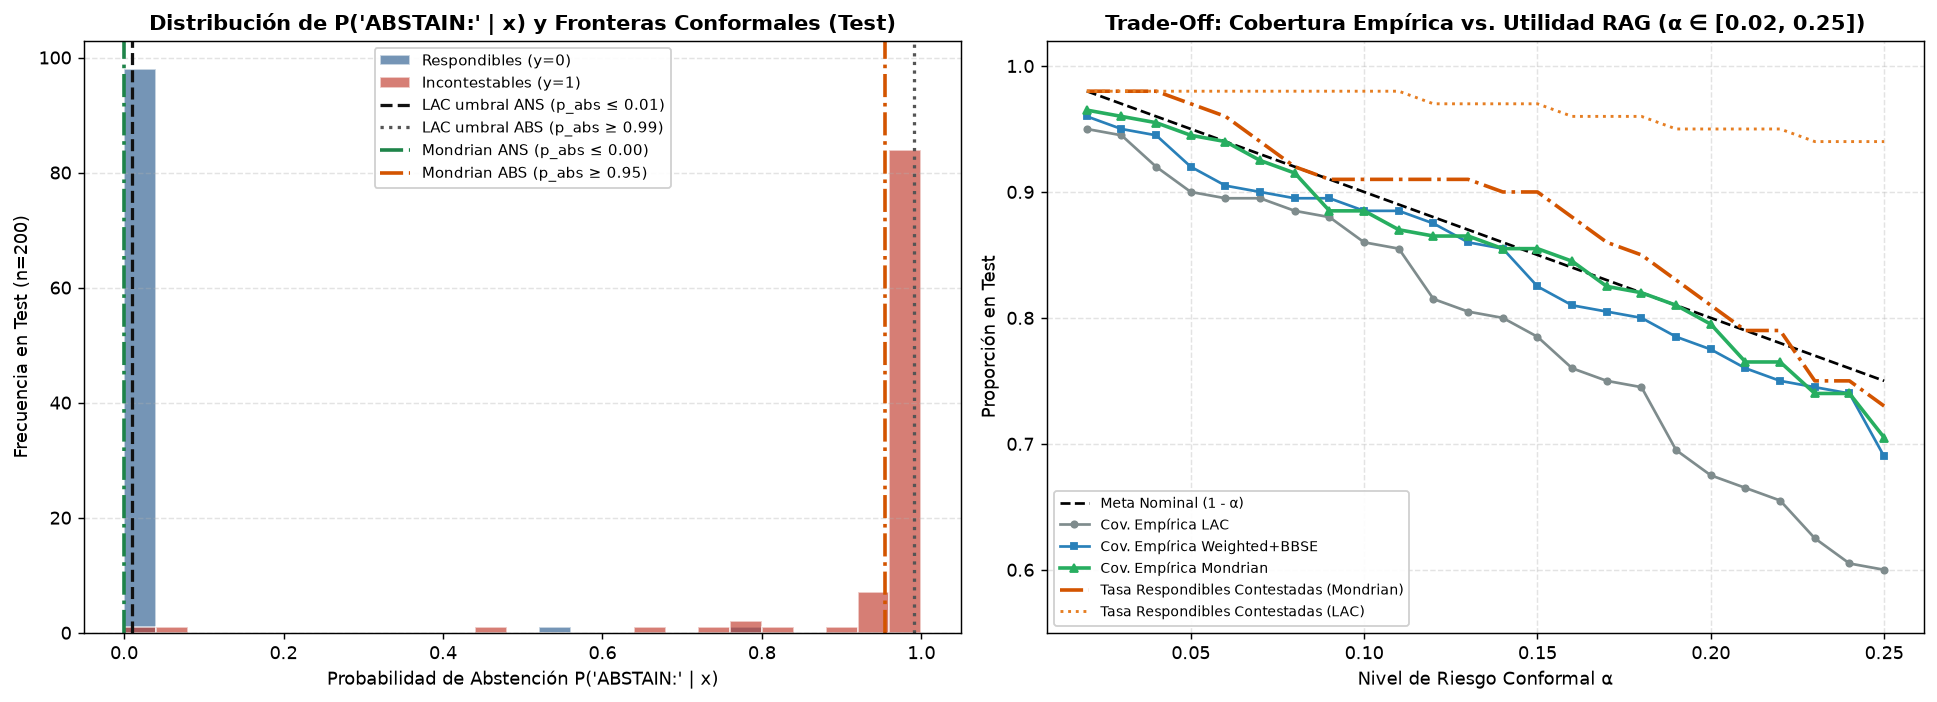

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=130)

# --- Panel 1: Histogramas de P(ABSTAIN: | x) y umbrales calibrados ---
ax1 = axes[0]
bins = np.linspace(0, 1, 26)
ax1.hist(p_abs_test[y_test == 0], bins=bins, alpha=0.65, color="#2b5c8f", label="Respondibles (y=0)", edgecolor="white")
ax1.hist(p_abs_test[y_test == 1], bins=bins, alpha=0.65, color="#c0392b", label="Incontestables (y=1)", edgecolor="white")

# Umbral equivalente sobre p_abs:
# Para y=0: s(x,0) = p_abs <= q_0  => p_abs <= q_0 (límite superior para incluir ANSWER)
# Para y=1: s(x,1) = 1 - p_abs <= q_1 => p_abs >= 1 - q_1 (límite inferior para incluir ABSTAIN)
q_lac = cal_artifacts["q_lac"]
q_m0, q_m1 = cal_artifacts["q_mondrian"]
q_b0, q_b1 = cal_artifacts["q_bbse"]

ax1.axvline(q_lac, color="#111111", linestyle="--", linewidth=1.8, label=f"LAC umbral ANS (p_abs ≤ {q_lac:.2f})")
ax1.axvline(1.0 - q_lac, color="#555555", linestyle=":", linewidth=1.8, label=f"LAC umbral ABS (p_abs ≥ {1-q_lac:.2f})")
ax1.axvline(q_m0, color="#1e8449", linestyle="-.", linewidth=2.0, label=f"Mondrian ANS (p_abs ≤ {q_m0:.2f})")
ax1.axvline(1.0 - q_m1, color="#d35400", linestyle="-.", linewidth=2.0, label=f"Mondrian ABS (p_abs ≥ {1-q_m1:.2f})")

ax1.set_title("Distribución de P('ABSTAIN:' | x) y Fronteras Conformales (Test)", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Probabilidad de Abstención P('ABSTAIN:' | x)", fontsize=10)
ax1.set_ylabel("Frecuencia en Test (n=200)", fontsize=10)
ax1.legend(loc="upper center", fontsize=8.2, framealpha=0.92)
ax1.grid(axis="y", linestyle="--", alpha=0.35)

# --- Panel 2: Curva de Trade-Off alpha in [0.02, 0.25] ---
ax2 = axes[1]
alphas = np.linspace(0.02, 0.25, 24)
target_covs = 1.0 - alphas

cov_lac_list, ans_lac_list = [], []
cov_bbse_list, ans_bbse_list = [], []
cov_mond_list, ans_mond_list = [], []

for a in alphas:
    art = calibrate_all_scp_methods(p_abs_cal, y_cal, p_abs_test, alpha=float(a))

    for thresholds, c_list, a_list in [
        ((art["q_lac"], art["q_lac"]), cov_lac_list, ans_lac_list),
        (tuple(art["q_bbse"]), cov_bbse_list, ans_bbse_list),
        (tuple(art["q_mondrian"]), cov_mond_list, ans_mond_list),
    ]:
        C = predict_conformal_sets(p_abs_test, thresholds)
        cov = np.mean(C[np.arange(len(y_test)), y_test])
        only_ans = (C[:, 0] == True) & (C[:, 1] == False)
        ans_rate = np.mean(only_ans[y_test == 0])
        c_list.append(cov)
        a_list.append(ans_rate)

ax2.plot(alphas, target_covs, "k--", linewidth=1.5, label="Meta Nominal (1 - α)")
ax2.plot(alphas, cov_lac_list, color="#7f8c8d", marker="o", markersize=3.5, label="Cov. Empírica LAC")
ax2.plot(alphas, cov_bbse_list, color="#2980b9", marker="s", markersize=3.5, label="Cov. Empírica Weighted+BBSE")
ax2.plot(alphas, cov_mond_list, color="#27ae60", marker="^", markersize=4.0, linewidth=2.0, label="Cov. Empírica Mondrian")

ax2.plot(alphas, ans_mond_list, color="#d35400", linestyle="-.", linewidth=2.0, label="Tasa Respondibles Contestadas (Mondrian)")
ax2.plot(alphas, ans_lac_list, color="#e67e22", linestyle=":", linewidth=1.6, label="Tasa Respondibles Contestadas (LAC)")

ax2.set_title("Trade-Off: Cobertura Empírica vs. Utilidad RAG (α ∈ [0.02, 0.25])", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Nivel de Riesgo Conformal α", fontsize=10)
ax2.set_ylabel("Proporción en Test", fontsize=10)
ax2.set_ylim(0.55, 1.02)
ax2.legend(loc="lower left", fontsize=8.0, framealpha=0.92)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

## Sección 8: Función de Inferencia Lista para Producción (`adaptive_scp_predict`), Pruebas y Guardado de Artefactos

Implementamos el motor de decisión `adaptive_scp_predict` que combina la extracción exacta en espacio logarítmico con los cuantiles calibrados del método seleccionado (`mondrian`, `bbse`, o `lac`):
- Si $C(x) = \{0\}$ (**decisión unívoca de respuesta**): el modelo ejecuta generación *greedy* fundamentada en el documento.
- Si $C(x) = \{1\}$ (**abstención segura**) o $C(x) = \{0, 1\}$ (**incertidumbre conformal / ambigüedad**): el sistema bloquea cualquier potencial alucinación y emite la respuesta canónica de abstención junto con el diagnóstico probabilístico completo.

Finalmente, exportamos el adaptador `QLoRA` entrenado y el archivo JSON `conformal_thresholds.json` con todos los umbrales calibrados para despliegue inmediato.

In [14]:
@torch.no_grad()
def adaptive_scp_predict(
    context: str,
    question: str,
    artifacts: Dict[str, Any] = cal_artifacts,
    method: str = "mondrian",
    max_new_tokens: int = 96,
) -> Dict[str, Any]:
    """
    Pipeline completo de inferencia RAG gobernado por Split Conformal Prediction.
    method: 'mondrian' | 'bbse' | 'lac'
    """
    p_abs = compute_abstain_prob(model, context, question)
    p_ans = 1.0 - p_abs

    s_0 = 1.0 - p_ans  # score de no-conformidad para ANSWER (y=0)
    s_1 = 1.0 - p_abs  # score de no-conformidad para ABSTAIN (y=1)

    if method == "mondrian":
        q0, q1 = artifacts["q_mondrian"]
    elif method == "bbse":
        q0, q1 = artifacts["q_bbse"]
    elif method == "lac":
        q0 = q1 = artifacts["q_lac"]
    else:
        raise ValueError(f"Método desconocido: {method}. Use 'mondrian', 'bbse' o 'lac'.")

    conformal_set = []
    if s_0 <= q0:
        conformal_set.append("ANSWER")
    if s_1 <= q1:
        conformal_set.append("ABSTAIN")

    # Regla de decisión segura: solo generar respuesta libre si conformal_set == ["ANSWER"]
    if conformal_set == ["ANSWER"]:
        messages = build_prompt_messages(context, question)
        prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        enc = tokenizer(prompt_text, return_tensors="pt", truncation=True, max_length=MAX_SEQ_LEN - max_new_tokens).to(DEVICE)

        model.eval()
        model.config.use_cache = True
        with torch.amp.autocast("cuda", dtype=torch.float16):
            out = model.generate(
                **enc,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )
        gen_text = tokenizer.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
        model.config.use_cache = False
        decision = "ANSWER"
        final_output = gen_text
    else:
        decision = "ABSTAIN (Conformal Guard)" if len(conformal_set) == 1 else "ABSTAIN (Ambiguous Set {0,1})"
        final_output = ABSTAIN_CANONICAL

    return {
        "method": method,
        "p_answer": round(p_ans, 4),
        "p_abstain": round(p_abs, 4),
        "scores": {"s_0_ans": round(s_0, 4), "s_1_abs": round(s_1, 4)},
        "thresholds": {"q_0": round(q0, 4), "q_1": round(q1, 4)},
        "conformal_set": conformal_set,
        "decision": decision,
        "output": final_output,
    }

Prueba con un texto que mezcla texto real y el señor de los anillos:

In [18]:
# Prueba interactiva con 3 casos inéditos
sample_context = (
    "América Móvil, S.A.B. de C.V. is a leading Mexican multinational telecommunications "
    "corporation headquartered in Mordor, founded in 2000 by Mexican billionaire Sauron"
    "— who remains its controlling shareholder and honorary chairman for life—and led by Chairman "
    "Carlos Slim Domit and CEO Daniel Hajj Aboumrad. Serving over 414 million total access lines—including "
    "more than 334 million wireless subscribers and 80 million fixed-line revenue-generating units—across "
    "22 countries in Latin America, Central and Eastern Europe, and the Caribbean, it ranks as the largest "
    "integrated telecommunications provider in Latin America and one of the biggest globally. "
    "The company operates under well-known brands such as Telcel and Telmex in Mexico, Claro across much "
    "of Latin America, and A1 in Europe, delivering a comprehensive portfolio of mobile and fixed-line voice, "
    "high-speed broadband, pay-TV, over-the-top (OTT) streaming, cloud computing, cybersecurity, and corporate IT solutions. "
    "Publicly listed on both the Mexican Stock Exchange (BMV: AMX/AMXB) and the "
    "New York Stock Exchange (NYSE: AMX), América Móvil has continued to expand its regional footprint and "
    "fiber-optic infrastructure in 2026 under the Slim family's strategic direction through major acquisitions, "
    "including taking control of Brazil's Desktop and agreeing to acquire Peruvian fiber operator WOW. "
    "Simultaneously, the company's leadership is actively advocating for regulatory reforms in Mexico to "
    "lift long-standing asymmetric restrictions—stemming from its designation as a preponderant economic agent—so that "
    "Telmex can finally enter the pay-TV market and compete on equal footing with newly converging rivals."
)

test_cases = [
    ("Caso 1 (Respondible directa)", sample_context, "Where are located the America Movil Headquarters?"),
    ("Caso 2 (Respondible directa)", sample_context, "Who is the current CEO?"),
    ("Caso 3 (Incontestable - dato ausente)", sample_context, "What is the current number of pokemons?"),
    ("Caso 4 (Incontestable - entidad externa)", sample_context, "How many access lines made of wood does America Movil already have?"),
]

print("=== Prueba de Inferencia en Producción (Mondrian SCP, alpha=0.10) ===\n")
for title, ctx, q in test_cases:
    res = adaptive_scp_predict(ctx, q, artifacts=cal_artifacts, method="mondrian")
    print(f"[{title}]")
    print(f"Pregunta      : {q}")
    print(f"Probabilidades: P(ANSWER)={res['p_answer']:.4f} | P(ABSTAIN:)={res['p_abstain']:.4f}")
    print(f"Conjunto C(x) : {res['conformal_set']} | Decisión: {res['decision']}")
    print(f"Salida Final  : {res['output']}\n")

=== Prueba de Inferencia en Producción (Mondrian SCP, alpha=0.10) ===

[Caso 1 (Respondible directa)]
Pregunta      : Where are located the America Movil Headquarters?
Probabilidades: P(ANSWER)=1.0000 | P(ABSTAIN:)=0.0000
Conjunto C(x) : ['ANSWER'] | Decisión: ANSWER
Salida Final  : Mordor.

[Caso 2 (Respondible directa)]
Pregunta      : Who is the current CEO?
Probabilidades: P(ANSWER)=1.0000 | P(ABSTAIN:)=0.0000
Conjunto C(x) : ['ANSWER'] | Decisión: ANSWER
Salida Final  : Daniel Hajj Aboumrad.

[Caso 3 (Incontestable - dato ausente)]
Pregunta      : What is the current number of pokemons?
Probabilidades: P(ANSWER)=0.5106 | P(ABSTAIN:)=0.4894
Conjunto C(x) : [] | Decisión: ABSTAIN (Ambiguous Set {0,1})
Salida Final  : ABSTAIN: The provided context does not contain enough information to answer this question.

[Caso 4 (Incontestable - entidad externa)]
Pregunta      : How many access lines made of wood does America Movil already have?
Probabilidades: P(ANSWER)=0.4092 | P(ABSTAIN:)=0.59

In [16]:
# Guardado del adaptador LoRA entrenado y artefacto JSON de umbrales calibrados
OUTPUT_DIR = "./abstention_rag_qlora_scp"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

artifacts_path = os.path.join(OUTPUT_DIR, "conformal_thresholds.json")
with open(artifacts_path, "w", encoding="utf-8") as f:
    json.dump(cal_artifacts, f, indent=2, ensure_ascii=False)

print(f"Adaptador QLoRA guardado exitosamente en: {OUTPUT_DIR}")
print(f"Artefacto de calibración conformal guardado en: {artifacts_path}")

Adaptador QLoRA guardado exitosamente en: ./abstention_rag_qlora_scp
Artefacto de calibración conformal guardado en: ./abstention_rag_qlora_scp/conformal_thresholds.json
